Objectif : Améliorer la précision du PINN pour les faibles viscosités

Sources : [Surrogate modeling for fluid flows based on physics-constrained deep
learning without simulation data](https://reader.elsevier.com/reader/sd/pii/S004578251930622X?token=AA07BED4AF49DDD062CCC26F45494E78C0D744A133E1B0A6547E66F5319F4FADC2A53C683A39F7C39B16A0A2F68ABBCD&originRegion=eu-west-1&originCreation=20220228112931)

# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

# Paramètres

In [2]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)
viscosity = tf.constant(1e-4, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,), dtype=DTYPE)

## Data generation

In [3]:
def gen_train_data(N_0=100, N_b=100, N_r=10000):

  # Set random seed for reproducible results
  tf.random.set_seed(0)

  # Draw uniform sample points for initial boundary data
  t_0 = tf.ones((N_0,1), dtype=DTYPE)*lb[0]
  x_0 = tf.random.uniform((N_0,1), lb[1], ub[1], dtype=DTYPE)
  X_0 = tf.concat([t_0, x_0], axis=1)

  # Evaluate intitial condition at x_0
  u_0 = fun_u_0(x_0)

  # Boundary data
  t_b = tf.random.uniform((N_b,1), lb[0], ub[0], dtype=DTYPE)
  x_b = lb[1] + (ub[1] - lb[1]) * tf.keras.backend.random_bernoulli((N_b,1), 0.5, dtype=DTYPE)
  X_b = tf.concat([t_b, x_b], axis=1)

  # Evaluate boundary condition at (t_b,x_b)
  u_b = fun_u_b(t_b, x_b)
  u_b = tf.expand_dims(u_b, -1)

  # Draw uniformly sampled collocation points
  t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
  x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
  X_r = tf.concat([t_r, x_r], axis=1)

  # Collect boundary and inital data in lists
  X_data = tf.concat([X_0, X_b], axis=0)
  u_data = tf.concat([u_0, u_b], axis=0)

  return X_r, X_data, u_data

In [4]:
X_r, X_data, u_data = gen_train_data(1000,1000,100_000)

In [5]:
def u_p(X):
    out = tf.cond( tf.equal(X[0,0],0.0), true_fn=lambda : fun_u_0(X[:,1]), false_fn=lambda : fun_u_b(X[:,0],X[:,1]), name=None )
    return tf.expand_dims(out, -1)

def psi(X):
    t = X[:,0:1]
    x = X[:,1:2]
    return (tf.sqrt(t)*(x+1)**2*(1-x)**2)

## PINN model

In [6]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)
        
        
        
    def call(self, X, training=False):
        """Forward-pass through neural network."""
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        
        return Y
        
        return u_p(X) + psi(X)*Y

In [7]:
class PINNSolver():
    def __init__(self, model, X_r):
        self.model = model
        
        # Store collocation points
        self.t = X_r[:,0:1]
        self.x = X_r[:,1:2]
        
        # Initialize history of losses and global iteration counter
        self.hist = []
        self.iter = 0
        
    def get_r(self):
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(self.t)
            tape.watch(self.x)
            
            # Compute current values u(t,x)
            u = self.model(tf.stack([self.t[:,0], self.x[:,0]], axis=1))
            u2 = tf.square(u)
            
            u_x = tape.gradient(u, self.x)
            
        u_t = tape.gradient(u, self.t)
        u_xx = tape.gradient(u_x, self.x)
        u2_x = tape.gradient(u2, self.x)

        del tape
        
        return u_t + u2_x/2. - viscosity * u_xx
    
    def loss_fn(self, X, u):
        
        # Compute phi_r
        r = self.get_r()
        phi_r = tf.reduce_mean(tf.square(r))
        
        # Initialize loss
        loss = phi_r

        # Add phi_0 and phi_b to the loss
        u_pred = self.model(X)
        loss += tf.reduce_mean(tf.square(u - u_pred))
        
        return loss
    
    def get_grad(self, X, u):
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(X, u)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    
    def fun_r(self, t, x, u, u_t, u_x, u_xx):
        """Residual of the PDE"""
        return u_t + u * u_x - viscosity * u_xx
    
    def solve_with_TFoptimizer(self, optimizer, X, u, N=1001):
        """This method performs a gradient descent type optimization."""
        
        @tf.function
        def train_step():
            loss, grad_theta = self.get_grad(X, u)
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
        
        for i in range(N):
            
            loss = train_step()
            
            self.current_loss = loss.numpy()
            self.callback()

    def solve_with_ScipyOptimizer(self, X, u, method='L-BFGS-B'):
        
        def get_weight_tensor():
            """Function to return current variables of the model
            as 1d tensor as well as corresponding shapes as lists."""
            
            weight_list = []
            shape_list = []
            
            # Loop over all variables, i.e. weight matrices, bias vectors and unknown parameters
            for v in self.model.variables:
                shape_list.append(v.shape)
                weight_list.extend(v.numpy().flatten())
                
            weight_list = tf.convert_to_tensor(weight_list)
            return weight_list, shape_list

        x0, shape_list = get_weight_tensor()
        
        def set_weight_tensor(weight_list):
            """Function which sets list of weights
            to variables in the model."""
            idx = 0
            for v in self.model.variables:
                vs = v.shape
                
                # Weight matrices
                if len(vs) == 2:  
                    sw = vs[0]*vs[1]
                    new_val = tf.reshape(weight_list[idx:idx+sw],(vs[0],vs[1]))
                    idx += sw
                
                # Bias vectors
                elif len(vs) == 1:
                    new_val = weight_list[idx:idx+vs[0]]
                    idx += vs[0]
                    
                # Variables (in case of parameter identification setting)
                elif len(vs) == 0:
                    new_val = weight_list[idx]
                    idx += 1
                    
                # Assign variables (Casting necessary since scipy requires float64 type)
                v.assign(tf.cast(new_val, DTYPE))
        
        def get_loss_and_grad(w):
            """Function that provides current loss and gradient
            w.r.t the trainable variables as vector. This is mandatory
            for the LBFGS minimizer from scipy."""
            
            # Update weights in model
            set_weight_tensor(w)
            # Determine value of \phi and gradient w.r.t. \theta at w
            loss, grad = self.get_grad(X, u)
            
            # Store current loss for callback function            
            loss = loss.numpy().astype(np.float64)
            self.current_loss = loss            
            
            # Flatten gradient
            grad_flat = []
            for g in grad:
                grad_flat.extend(g.numpy().flatten())
            
            # Gradient list to array
            grad_flat = np.array(grad_flat,dtype=np.float64)
            
            # Return value and gradient of \phi as tuple
            return loss, grad_flat
        
        scipy.optimize.minimize(fun=get_loss_and_grad,
                                       x0=x0,
                                       jac=True,
                                       method=method,
                                       callback=self.callback,
                                       options={'maxiter': 2000,
                                                'maxfun': 50000,
                                                'maxcor': 50,
                                                'maxls': 50,
                                                'ftol': 1.0*np.finfo(float).eps})
        
    def callback(self, xr=None):
        
        if self.iter % 100 == 0:
            print('Iteration {:05d}: loss = {:10.8e}'.format(self.iter,self.current_loss))
        self.hist.append(self.current_loss)
        self.iter+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

In [8]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=8, num_neurons_per_layer=20, activation='swish')
model.build(input_shape=(None,2))

# Initilize PINN solver
solver = PINNSolver(model, X_r)

In [9]:
solver = PINNSolver(model, X_r)

In [10]:
def loss_fn(u_pred, u):

    # Compute phi_r
    r = solver.get_r()
    phi_r = tf.reduce_mean(tf.square(r))

    # Initialize loss
    loss = phi_r

    # Add phi_0 and phi_b to the loss
    loss += tf.reduce_mean(tf.square(u - u_pred))

    return loss

In [11]:
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.9,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_data, u_data, N=4001)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 00000: loss = 2.48423353e-01
Iteration 00100: loss = 2.45406911e-01
Iteration 00200: loss = 2.25920424e-01
Iteration 00300: loss = 2.08367482e-01
Iteration 00400: loss = 2.05233589e-01
Iteration 00500: loss = 2.03019351e-01
Iteration 00600: loss = 2.00813085e-01
Iteration 00700: loss = 1.97206169e-01
Iteration 00800: loss = 1.84470132e-01
Iteration 00900: loss = 1.27271682e-01
Iteration 01000: loss = 1.05595179e-01
Iteration 01100: loss = 1.00799650e-01
Iteration 01200: loss = 9.89124253e-02
Iteration 01300: loss = 9.80290696e-02
Iteration 01400: loss = 9.73455608e-02
Iteration 01500: loss = 9.65607613e-02
Iteration 01600: loss = 9.56615061e-02
Iteration 01700: loss = 9.48246717e-02
Iteration 01800: loss = 9.41524804e-02
Iteration 01900: loss = 9.35992450e-02
Iteration 02000: loss = 9.30872485e-02
Iteration 02100: loss = 9.26145762e-02
Iteration 02200: loss = 9.21022892e-02
Iteration 02300: loss = 9.15282369e-02
Iteration 02400: loss = 9.08734947e-02
Iteration 02500: loss = 9

In [12]:
t0 = time()
try: 
  solver.solve_with_ScipyOptimizer(X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))


Training time: 10.154927492141724 seconds


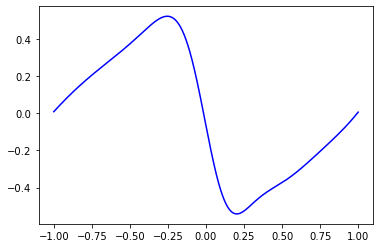

In [28]:
N = 1000
T =  1.0 * np.ones(N+1)
xspace = np.linspace(lb[1], ub[1], N + 1)
nuspace = 0.5 * np.ones(N+1)
Xgrid = np.vstack([T.flatten(),xspace.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

plt.plot(xspace,upred, 'b-');

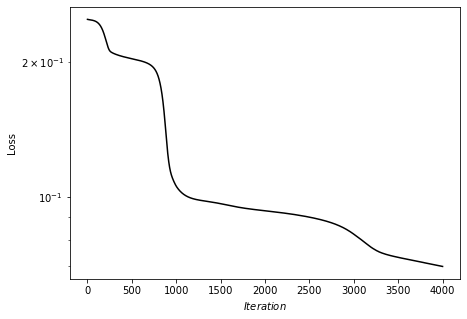

In [29]:
solver.plot_loss_history();

# Affichage du résidu

In [15]:
from mpl_toolkits.mplot3d import Axes3D

In [16]:
def get_r(model, X_r):
    
    with tf.GradientTape(persistent=True) as tape:
        # Split t and x to compute partial derivatives
        t, x = X_r[:, 0:1], X_r[:,1:2]

        # Variables t and x are watched during tape
        # to compute derivatives u_t and u_x
        tape.watch(t)
        tape.watch(x)

        # Determine residual 
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)

        # Compute gradient u_x within the GradientTape
        # since we need second derivatives
        u_x = tape.gradient(u, x)
            
    u_t = tape.gradient(u, t)
    u_xx = tape.gradient(u_x, x)
    u2_x = tape.gradient(u2, x)

    del tape

    return u_t +  u2_x/2 - viscosity * u_xx

In [17]:
# Set up meshgrid
N = 200
tspace = np.linspace(lb[0], ub[0], N + 1)
xspace = np.linspace(lb[1], ub[1], N + 1)
T, X = np.meshgrid(tspace, xspace)
X_test_grid = np.vstack([T.flatten(),X.flatten()]).T

# Determine residual
residu = get_r(model,tf.cast(X_test_grid,DTYPE))

# Reshape
R = residu.numpy().reshape(N+1,N+1)

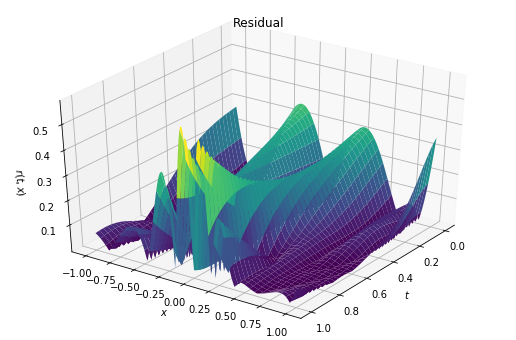

In [18]:
# Surface plot of residual
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, np.abs(R), cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('$r(t,x)$')
ax.set_title('Residual');

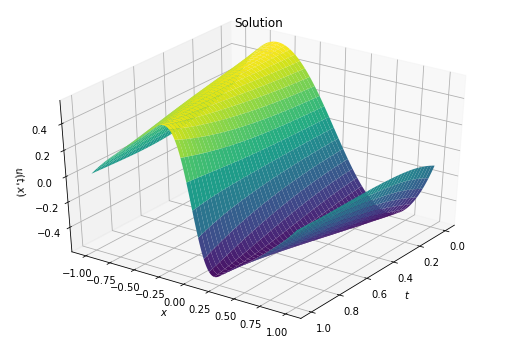

In [19]:
U = model(X_test_grid).numpy().reshape(N+1,N+1)
# Surface plot of residual
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, U, cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('$u(t,x)$')
ax.set_title('Solution');

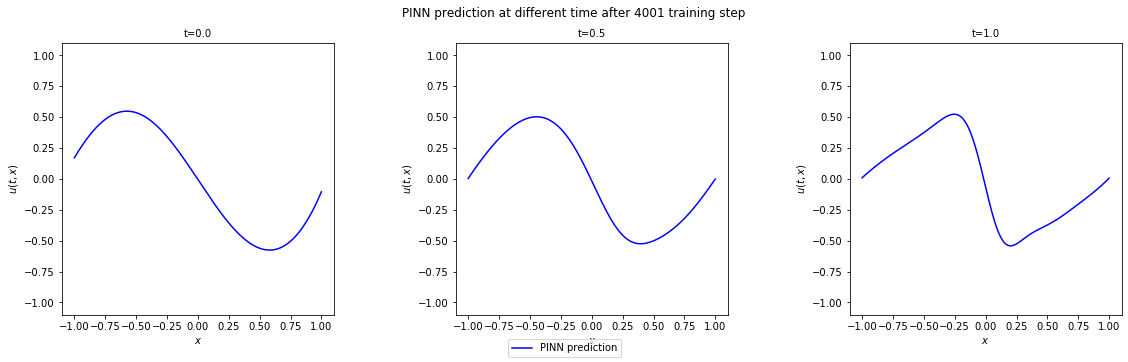

In [20]:
fig, axs = plt.subplots(1, 3, figsize=(20,5))

N=600
xspace = np.linspace(lb[1], ub[1], N + 1)

all_times=[0.,0.5,1.0]
for i_t, end_time in enumerate(all_times):

    T, X = np.meshgrid(end_time, xspace)
    Xgrid = np.vstack([T.flatten(),X.flatten()]).T
    upred = model(tf.cast(Xgrid,DTYPE))

    axs[i_t].plot(xspace,upred, 'b-', label="PINN prediction")
    axs[i_t].set_title("t=" + str(end_time), fontsize = 10)
    axs[i_t].set_xlabel('$x$')
    axs[i_t].set_ylabel('$u(t,x)$')    
    axs[i_t].axis('square')
    axs[i_t].set_xlim([-1.1,1.1])
    axs[i_t].set_ylim([-1.1,1.1]);

handles, labels = axs[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4);

plt.suptitle("PINN prediction at different time after {} training step".format(solver.iter));

# Idem avec l'entropie 

In [21]:
def get_entropy(model, X_r):
    
    with tf.GradientTape(persistent=True) as tape:
        # Split t and x to compute partial derivatives
        t, x = X_r[:, 0:1], X_r[:,1:2]

        # Variables t and x are watched during tape
        # to compute derivatives u_t and u_x
        tape.watch(t)
        tape.watch(x)

        # Determine residual 
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)
        u3 = tf.pow(u,3.0)

        # Compute gradient u_x within the GradientTape
        # since we need second derivatives
        u2_x = tape.gradient(u2, x)
            
    eta_t = tape.gradient(u2, t)
    q_x = tape.gradient(u3, x)
    eta_xx = tape.gradient(u2_x, x)

    del tape

    return eta_t/2 +  q_x/3 - viscosity * eta_xx

In [22]:
# Set up meshgrid
N = 100
tspace = np.linspace(lb[0], ub[0], N + 1)
xspace = np.linspace(lb[1], ub[1], N + 1)
T, X = np.meshgrid(tspace, xspace)
X_test_grid = np.vstack([T.flatten(),X.flatten()]).T

# Determine residual
entropy = get_entropy(model,tf.cast(X_test_grid,DTYPE))

# Reshape
S = entropy.numpy().reshape(N+1,N+1)
S

array([[-0.04828733, -0.04652961, -0.04480916, ...,  0.00031818,
         0.00034648,  0.00037124],
       [-0.04673726, -0.0452404 , -0.04378196, ...,  0.00130893,
         0.0012986 ,  0.00128217],
       [-0.04268382, -0.04138821, -0.04013613, ...,  0.00203506,
         0.00197966,  0.00191608],
       ...,
       [-0.03912991, -0.03736816, -0.0355352 , ..., -0.00064099,
        -0.00067567, -0.00070865],
       [-0.04165746, -0.03933781, -0.03700698, ..., -0.00067699,
        -0.00068842, -0.00069724],
       [-0.03815227, -0.03535536, -0.03262862, ...,  0.00010237,
         0.00014763,  0.00019634]], dtype=float32)

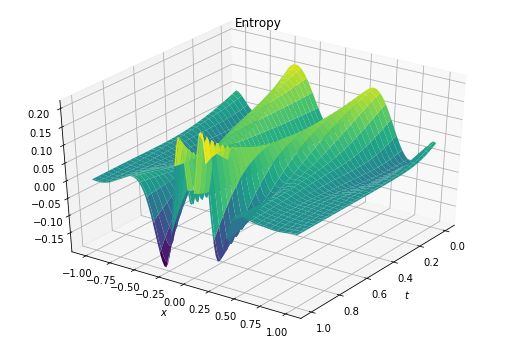

In [23]:
# Surface plot of residual
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, -S, cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('')
ax.set_title('Entropy');